# Julia から Wolfram Engine を呼び出す — 式変形を Julia で使う

[MathLink.jl](https://github.com/JuliaInterop/MathLink.jl) を使って Julia から Wolfram Engine を呼び出します。

Wolfram に式変形（展開・因数分解・部分分数分解・三角関数の変形など）をさせ，結果を $\LaTeX$ で表示します。  
変形の前後の式を **Julia の関数**にして，数値を代入して等しいことを確かめたり，グラフを重ねたりします。

- 展開 `Expand`・因数分解 `Factor`・係数 `CoefficientList`
- 整式の割り算 `PolynomialQuotientRemainder`
- 分数式：通分 `Together`・部分分数分解 `Apart`
- 根号：有理化・二重根号
- 三角関数：加法定理 `TrigExpand`・積和 `TrigReduce`・合成
- 恒等式・等式の証明 `Simplify`

**注意**：無料版 Wolfram Engine は同時に起動できるカーネル数に上限があります。他のノートブックや `wolframscript` が動いたままだと接続に失敗するので，使い終わったカーネルは停止してください。

## 0. 準備

共通の関数（表示 `tex`, `showtex`，変換 `to_expr`, `to_value`, `to_function` など）は `wolfram_common.jl` にまとめてあります。  
このノートブックと同じフォルダに置いて，`include` で読み込みます。

In [1]:
# import Pkg; Pkg.add(["MathLink", "SpecialFunctions", "Plots"])
# Pkg.add(url="https://github.com/ujimushi/PlotsGRBackendFontJaEmoji.jl")   # グラフの日本語表示用

In [2]:
include("wolfram_common.jl")      # MathLink の読み込みと，共通の関数
using Plots
using PlotsGRBackendFontJaEmoji   # グラフで日本語を使えるようにする

## 1. 基本：`Expand` と `Factor`

In [3]:
weval(W`Expand[(x + 2 y)^3]`)

W`Plus[Power[x, 3], Times[6, Power[x, 2], y], Times[12, x, Power[y, 2]], Times[8, Power[y, 3]]]`

In [4]:
weval(W`Factor[x^4 - 5 x^2 + 4]`)

W`Times[Plus[-2, x], Plus[-1, x], Plus[1, x], Plus[2, x]]`

## 2. このノートブックで使う関数

- `rewrite("操作", "式")`：Wolfram の操作（`Expand`, `Factor` など）を式に適用し，「元の式 = 結果」を表示して結果を返す
- `agree(w1, w2, :x, ...)`：2 つの式に乱数を代入して，値が一致するかを Julia で確かめる

In [5]:
# 「元の式 = 変形した式」を表示して，結果（Wolfram の式）を返す。opts は操作に渡す追加の引数
function rewrite(op::AbstractString, expr::AbstractString; opts="")
    res = weval(wparse("$op[$expr" * (isempty(opts) ? "" : ", $opts") * "]"))
    showtex(heldtex(expr) * " = " * tex(res))
    return res
end

# 2 つの式が等しいかを，乱数を代入して確かめる（恒等式の数値チェック）
function agree(w1, w2, vars::Symbol...; trials=5)
    f, g = to_function(w1, vars...), to_function(w2, vars...)
    all(1:trials) do _
        p = 0.5 .+ rand(length(vars))                 # 0.5〜1.5 の乱数
        isapprox(f(p...), g(p...); rtol=1e-9)
    end
end

agree (generic function with 1 method)

In [6]:
e1 = "(x + 2 y)^3"
r1 = rewrite("Expand", e1)

to_expr(r1)                           # Julia の式

:(x ^ 3 + 6 * x ^ 2 * y + 12 * x * y ^ 2 + 8 * y ^ 3)

In [7]:
f = to_function(wparse(e1), :x, :y)   # 変形前
g = to_function(r1, :x, :y)           # 変形後
f(2, 3), g(2, 3), agree(wparse(e1), r1, :x, :y)

(512, 512, true)

## 3. 展開と係数

### 二項定理

$(a+b)^n$ を展開した係数は二項係数 ${}_n\mathrm{C}_k$ です。`CoefficientList` で係数を Julia の配列として取り出します。

In [8]:
rewrite("Expand", "(a + b)^5")
rewrite("Expand", "(x + 1)^6")
cw = weval(W`CoefficientList[(x + 1)^6, x]`)       # 定数項から順に並んだ係数

coef = to_value(cw)
coef, [binomial(6, k) for k in 0:6]                # Julia の binomial と一致

([1, 6, 15, 20, 15, 6, 1], [1, 6, 15, 20, 15, 6, 1])

In [9]:
# パスカルの三角形：Wolfram の係数と Julia の binomial を並べる
for n in 0:8
    c = to_value(weval(W`CoefficientList[(x + 1)^$n, x]`))
    println(lpad(join(c, "  "), 30 + 2n))
end

                             1
                            1  1
                           1  2  1
                          1  3  3  1
                         1  4  6  4  1
                      1  5  10  10  5  1
                    1  6  15  20  15  6  1
                  1  7  21  35  35  21  7  1
                1  8  28  56  70  56  28  8  1


### 係数の配列から多項式の値を計算する

Julia の `evalpoly(x, 係数)` は，係数の配列（定数項から順）から多項式の値を計算します。

In [10]:
pstr = "(2 x - 1)^3 (x + 2)"
pw_expanded = rewrite("Expand", pstr)
c = to_value(weval(wparse("CoefficientList[$pstr, x]")))

p = to_function(wparse(pstr), :x)
c, evalpoly(3, c), p(3)

([-2, 11, -18, 4, 8], 625, 625)

In [11]:
rewrite("Expand", "(x + y + z)^2")
rewrite("Expand", "(x + y) (x^2 - x y + y^2)")
rewrite("Expand", "(a + b + c) (a^2 + b^2 + c^2 - a b - b c - c a)")
c34 = weval(W`Coefficient[(2 x - 3 y)^7, x^3 y^4]`)
showtex("(2x - 3y)^7 \\text{ の } x^3 y^4 \\text{ の係数}\\quad " * tex(c34))
to_value(c34), binomial(7, 3) * 2^3 * (-3)^4      # 二項定理による計算と一致

(22680, 22680)

## 4. 因数分解

In [12]:
rewrite("Factor", "x^2 - 5 x + 6")
rewrite("Factor", "6 x^2 + 5 x y - 6 y^2")
rewrite("Factor", "x^3 + y^3")
rewrite("Factor", "x^4 + x^2 + 1")
rewrite("Factor", "x^4 + 4")
rewrite("Factor", "a^3 + b^3 + c^3 - 3 a b c")
rewrite("Factor", "x^2 - y^2 + 2 y - 1")
rewrite("Factor", "a^2 (b - c) + b^2 (c - a) + c^2 (a - b)")
rewrite("Factor", "x^6 - 1");

### どの範囲の数で因数分解するか

`Factor` は有理数の範囲で因数分解します。`Extension` で使ってよい数を増やせます。

In [13]:
rewrite("Factor", "x^4 - 4")                                      # 有理数の範囲
rewrite("Factor", "x^4 - 4"; opts="Extension -> Sqrt[2]")         # √2 を使ってよい（実数の範囲）
rewrite("Factor", "x^4 - 4"; opts="Extension -> {Sqrt[2], I}")    # 虚数単位も使ってよい（複素数の範囲）
rewrite("Factor", "x^2 + 1"; opts="Extension -> I");

### 因数分解とグラフ

因数分解した形からは，$x$ 軸との交点（解）がすぐにわかります。変形前後の式を Julia の関数にして重ねて描きます。

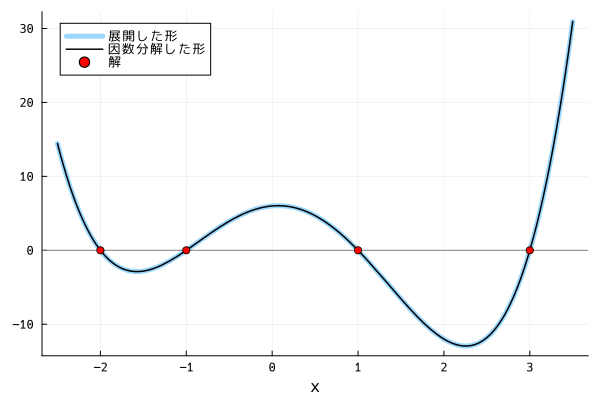

In [14]:
qstr = "x^4 - x^3 - 7 x^2 + x + 6"
qw = rewrite("Factor", qstr)
roots = to_value(weval(wparse("x /. Solve[$qstr == 0, x]")))

q1 = to_function(wparse(qstr), :x); q2 = to_function(qw, :x)
plot(q1, -2.5, 3.5; lw=5, alpha=0.4, label="展開した形", xlabel="x")
plot!(q2, -2.5, 3.5; lw=1.5, color=:black, label="因数分解した形")
hline!([0]; color=:gray, label="")
scatter!(roots, zero(roots); color=:red, label="解")

## 5. 整式の割り算

`PolynomialQuotientRemainder[A, B, x]` は，商と余りを `{商, 余り}` で返します。

In [15]:
Astr = "2 x^4 - 3 x^3 + x - 5"; Bstr = "x^2 - x + 2"
qrw = weval(wparse("PolynomialQuotientRemainder[$Astr, $Bstr, x]"))
showtex("\\left(" * heldtex(Astr) * "\\right) \\div \\left(" * heldtex(Bstr) * "\\right) :\\quad \\text{商 } " *
        tex(qrw.args[1]) * ",\\quad \\text{余り } " * tex(qrw.args[2]))

# 検算：A = B × 商 + 余り
A = to_function(wparse(Astr), :x); B = to_function(wparse(Bstr), :x)
Q = to_function(qrw.args[1], :x);  R = to_function(qrw.args[2], :x)
[(x, A(x), B(x) * Q(x) + R(x)) for x in (-2, 0, 1, 3)]

4-element Vector{Tuple{Int64, Int64, Int64}}:
 (-2, 49, 49)
 (0, -5, -5)
 (1, -5, -5)
 (3, 79, 79)

**剰余の定理**：$P(x)$ を $x - a$ で割った余りは $P(a)$。

In [16]:
Pstr = "x^3 - 4 x^2 + x + 6"
P = to_function(wparse(Pstr), :x)
for a in (1, 2, -1, 3)
    rem = to_value(weval(wparse("PolynomialRemainder[$Pstr, x - ($a), x]")))
    println("x - ($a) で割った余り: ", rem, "    P($a) = ", P(a))
end
rewrite("Factor", Pstr);              # 余りが 0 になる a が因数を与える（因数定理）

x - (1) で割った余り: 4    P(1) = 4
x - (2) で割った余り: 0    P(2) = 0
x - (-1) で割った余り: 0    P(-1) = 0
x - (3) で割った余り: 0    P(3) = 0


## 6. 分数式

### 通分・約分

In [17]:
rewrite("Together", "1/(x - 1) + 1/(x + 1)")
rewrite("Together", "1/(x (x + 1)) + 1/((x + 1) (x + 2))")
rewrite("Cancel", "(x^2 - 1)/(x^2 + 3 x + 2)")
rewrite("Simplify", "(1/x - 1/y)/(1/x + 1/y)");

### 部分分数分解

`Apart` は通分の逆の操作です。和や積分の計算で使います。

In [18]:
aw = rewrite("Apart", "1/(k (k + 1))")
rewrite("Apart", "1/(k (k + 2))")
rewrite("Apart", "(3 x + 5)/((x + 1) (x + 2))")
bw = rewrite("Apart", "(x^2 + 1)/(x (x - 1)^2)")
rewrite("Apart", "x^3/(x^2 - 1)");

In [19]:
# 部分分数に分けると，和が次々に消える（Julia で分数のまま確かめる）
term = to_function(aw, :k)
n = 10
[term(k) for k in 1:n], sum(term(k) for k in 1:n), 1 - 1 // (n + 1)

(Rational{Int64}[1//2, 1//6, 1//12, 1//20, 1//30, 1//42, 1//56, 1//72, 1//90, 1//110], 10//11, 10//11)

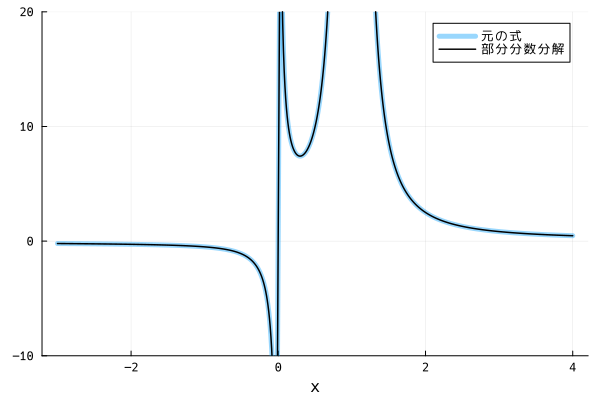

In [20]:
# 変形前後のグラフが重なることを確かめる
h1 = to_function(wparse("(x^2 + 1)/(x (x - 1)^2)"), :x); h2 = to_function(bw, :x)
xs = [x for x in range(-3, 4; length=701) if abs(x) > 0.02 && abs(x - 1) > 0.02]
plot(xs, h1.(xs); lw=5, alpha=0.4, label="元の式", ylims=(-10, 20), xlabel="x")
plot!(xs, h2.(xs); lw=1.5, color=:black, label="部分分数分解")

## 7. 根号を含む式

Wolfram には「分母の有理化」専用の関数がないので，いくつかの操作を組み合わせます。  
二重根号をはずすには `FunctionExpand` を使います。どちらも，いつでもうまくいくとは限りません。

In [21]:
# 分母の有理化：いったん代数的数の標準形（RootReduce）にしてから，根号の式に戻して整理する
rationalize = "Composition[FullSimplify, ToRadicals, RootReduce]"

s1 = rewrite(rationalize, "1/(Sqrt[3] - Sqrt[2])")
rewrite(rationalize, "1/(2 - Sqrt[3])")
rewrite(rationalize, "(Sqrt[5] + Sqrt[3])/(Sqrt[5] - Sqrt[3])")
rewrite(rationalize, "1/(1 + Sqrt[2] + Sqrt[3])")
rewrite("Expand", "(Sqrt[2] + Sqrt[3])^2")
rewrite("Simplify", "Sqrt[12] + Sqrt[27] - Sqrt[48]");

In [22]:
# 二重根号をはずす
s2 = rewrite("FunctionExpand", "Sqrt[5 + 2 Sqrt[6]]")
rewrite("FunctionExpand", "Sqrt[7 - 4 Sqrt[3]]")
rewrite("FunctionExpand", "Sqrt[4 - Sqrt[15]]")
rewrite("FunctionExpand", "Sqrt[3 + Sqrt[2]]");             # はずせない二重根号はそのまま返る

In [23]:
# Julia で数値を確かめる
to_value(s1), 1 / (sqrt(3) - sqrt(2)), to_value(s2), sqrt(5 + 2 * sqrt(6))

(3.1462643699419726, 3.1462643699419743, 3.1462643699419726, 3.146264369941972)

### 対称式と式の値

$x = \frac{\sqrt5 + 1}{2}$，$y = \frac{\sqrt5 - 1}{2}$ のとき，$x + y$，$xy$ から $x^2 + y^2$，$x^3 + y^3$ を求めます。  
`SymmetricReduction` は，対称式を基本対称式 $s_1 = x + y$，$s_2 = xy$ で表します。

In [24]:
for e in ("x^2 + y^2", "x^3 + y^3", "x^4 + y^4")
    sw = weval(wparse("First[SymmetricReduction[$e, {x, y}, {s1, s2}]]"))
    showtex(heldtex(e) * " = " * replace(tex(sw), r"\\text\{s(\d)\}" => s"s_\1"))
end

In [25]:
vals = "{x -> (Sqrt[5] + 1)/2, y -> (Sqrt[5] - 1)/2}"
for e in ("x + y", "x y", "x^2 + y^2", "x^3 + y^3", "x/y + y/x")
    v = weval(wparse("FullSimplify[$e /. $vals]"))
    showtex(heldtex(e) * " = " * tex(v))
end

## 8. 三角関数

### 加法定理・倍角・積和・和積

In [26]:
rewrite("TrigExpand", "Sin[a + b]")                # 加法定理
rewrite("TrigExpand", "Cos[a - b]")
rewrite("TrigExpand", "Tan[a + b]")
rewrite("TrigExpand", "Sin[2 x]")                  # 2 倍角
rewrite("TrigExpand", "Cos[3 x]")                  # 3 倍角
rewrite("TrigReduce", "Sin[a] Cos[b]")             # 積 → 和
rewrite("TrigReduce", "Sin[x]^2")                  # 半角（次数を下げる）
rewrite("TrigReduce", "Cos[x]^4")
rewrite("TrigFactor", "Sin[a] + Sin[b]");          # 和 → 積

### 三角関数の合成

$a\sin x + b\cos x = r\sin(x + \alpha)$ の形にまとめます。$r = \sqrt{a^2 + b^2}$，$\alpha$ は点 $(a, b)$ の偏角です。  
Wolfram で $r$, $\alpha$ を厳密に求め，両辺が等しいことも確かめます。変形前後のグラフは Julia で重ねます。

In [27]:
function compose(a::AbstractString, b::AbstractString)
    rw = weval(wparse("Simplify[Sqrt[($a)^2 + ($b)^2]]"))
    αw = weval(wparse("Arg[($a) + I ($b)]"))                     # 点 (a, b) の偏角
    lhs = "($a) Sin[x] + ($b) Cos[x]"
    rhsw = W"Times"(rw, W"Sin"(W"Plus"(W"x", αw)))
    ok = weval(W"FullSimplify"(W"Equal"(wparse(lhs), rhsw))) == W"True"
    # 右辺は HoldForm で包んで，sin(x + π/3) が cos(π/6 - x) に自動で書き換えられるのを止める
    showtex(tex(weval(wparse(lhs))) * " = " * tex(W"HoldForm"(rhsw)) * (ok ? "" : "\\quad\\text{（確認できませんでした）}"))
    return rhsw
end

c1  = "Sin[x] + Sqrt[3] Cos[x]"
cw1 = compose("1", "Sqrt[3]")
compose("1", "1")
compose("Sqrt[3]", "-1")
compose("3", "4");                    # α がきれいな角でないときは tan⁻¹ で表される

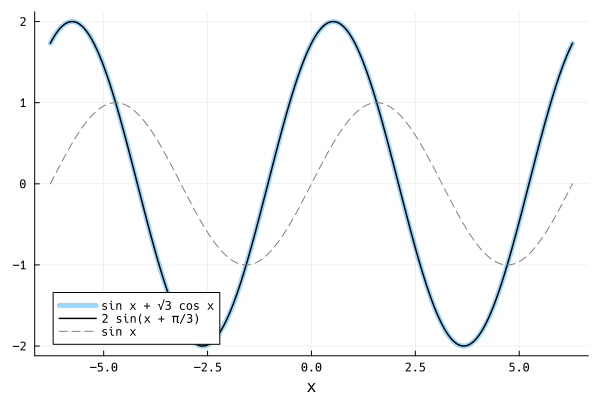

In [28]:
k1 = to_function(wparse(c1), :x); k2 = to_function(cw1, :x)
plot(k1, -2π, 2π; lw=5, alpha=0.4, label="sin x + √3 cos x", xlabel="x")
plot!(k2, -2π, 2π; lw=1.5, color=:black, label="2 sin(x + π/3)")
plot!(sin, -2π, 2π; ls=:dash, color=:gray, label="sin x")

In [29]:
# 最大値と，それを与える x（0 ≤ x < 2π）
mw = weval(wparse("Maximize[{$c1, 0 <= x < 2 Pi}, x]"))
showtex("\\max\\left(" * heldtex(c1) * "\\right) = " * tex(mw.args[1]) * "\\quad \\left(x = " * tex(mw.args[2].args[1].args[2]) * "\\right)")
to_value(mw)

2-element Vector{Any}:
 2
  (x = 0.5235987755982988,)

## 9. 指数・対数

In [30]:
rewrite("Simplify", "Log[2, 8] + Log[2, 1/4]")
rewrite("FullSimplify", "Log[2, 3] Log[3, 8]")               # 底の変換
rewrite("FullSimplify", "Log[10, 2] + Log[10, 5]")
rewrite("PowerExpand", "Log[x^2 y^3]")                       # 文字は正の数とみなして展開
rewrite("Simplify", "2^(x + 1) - 2^x")
rewrite("FullSimplify", "(2^x + 2^(-x))^2 - (2^x - 2^(-x))^2")
rewrite("Simplify", "Sqrt[x^2]"; opts="x > 0")               # 条件をつけて簡単にする
rewrite("Simplify", "Sqrt[x^2]"; opts="x < 0");

## 10. 恒等式・等式の証明

`Simplify[左辺 == 右辺]` が `True` なら恒等式です。条件のもとでの等式は，第 2 引数に条件を書きます。

In [31]:
# 恒等式かどうかを判定して表示する。cond は条件（省略可）
function identity_check(lhs::AbstractString, rhs::AbstractString; cond="")
    res = weval(wparse("FullSimplify[($lhs) == ($rhs)" * (isempty(cond) ? "" : ", $cond") * "]"))
    mark = res == W"True" ? "\\quad\\text{（成り立つ）}" : "\\quad\\text{（恒等式ではない：}" * tex(res) * "\\text{）}"
    showtex(heldtex(lhs) * " = " * heldtex(rhs) * (isempty(cond) ? "" : "\\quad \\left(" * heldtex(cond) * "\\right)") * mark)
    return res == W"True"
end

identity_check (generic function with 1 method)

In [32]:
identity_check("(a^2 + b^2) (c^2 + d^2)", "(a c + b d)^2 + (a d - b c)^2")
identity_check("Sin[x]^4 - Cos[x]^4", "1 - 2 Cos[x]^2")
identity_check("(1 + Tan[x]^2) Cos[x]^2", "1")
identity_check("a^3 + b^3 + c^3", "3 a b c"; cond="a + b + c == 0")       # 条件つきの等式
identity_check("a^3 + b^3 + c^3", "3 a b c")                              # 条件がなければ成り立たない
identity_check("(a + b)^2", "a^2 + b^2")

false

In [33]:
# Julia で数値を代入しても確かめられる（乱数で 5 回）
agree(wparse("(a^2 + b^2) (c^2 + d^2)"), wparse("(a c + b d)^2 + (a d - b c)^2"), :a, :b, :c, :d),
agree(wparse("(a + b)^2"), wparse("a^2 + b^2"), :a, :b)

(true, false)

### 恒等式の係数を決める

$\dfrac{3x + 5}{(x+1)(x+2)} = \dfrac{a}{x+1} + \dfrac{b}{x+2}$ がすべての $x$ で成り立つように $a, b$ を決めます（`SolveAlways`）。

In [34]:
abw = weval(W`First[SolveAlways[3 x + 5 == a (x + 2) + b (x + 1), x]]`)
showtex(join((tex(r.args[1]) * " = " * tex(r.args[2]) for r in abw.args), ",\\quad "))
to_value(abw)

(a = 2, b = 1)

## 11. うまくいかないとき

- **接続エラー（`AssertionError: nextpacket(...)` など）**：Wolfram Engine のカーネル数上限に達しています。他のノートブックのカーネルや `wolframscript` を止めてから，Julia カーネルを再起動してください。
- **思った形にならない**：「簡単な形」は 1 つではありません。`Simplify`，`FullSimplify`，`Expand`，`Factor`，`Together`，`Apart`，`Collect` を使い分けます。
- **$\sqrt{x^2}$ が $x$ にならない**：$x$ が負かもしれないためです。`opts="x > 0"` のように条件を付けます。
- **`Factor` で分解されない**：有理数の範囲では分解できない式です。`Extension` を指定します。
- **入力した式の表示順**：左辺は入力した形のまま，右辺は Wolfram の標準の順序（次数の高い順とは限らない）で表示されます。

In [35]:
# 文字について整理する：Collect
rewrite("Collect", "a x^2 + b x + x^2 - 3 x + a + 1"; opts="x")
rewrite("Collect", "(x + y + 1)^3"; opts="x");